# Task 5 — A real time series

This dataset is small and clean, so the real work is in choosing the right time representation and separating long-term trend from seasonal structure.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

path = Path('data') / 'flights.csv'
df = pd.read_csv(path)
df['date'] = pd.to_datetime(df['year'].astype(str) + '-' + df['month'].astype(str) + '-01')
df = df.sort_values('date').reset_index(drop=True)
df.head()


,year,month,passengers,date
0,1949,January,112,1949-01-01
1,1949,February,118,1949-02-01
2,1949,March,132,1949-03-01
3,1949,April,129,1949-04-01
4,1949,May,121,1949-05-01


## 1) Plot passengers over time
The key is to create a proper ordered time axis by combining year and month.


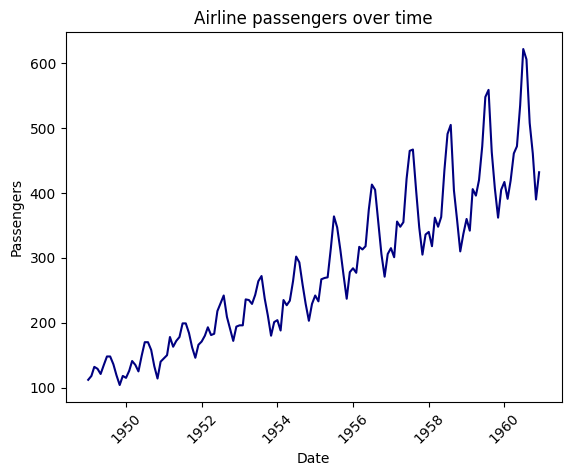

In [2]:
sns.lineplot(data=df, x='date', y='passengers', color='navy')
plt.title('Airline passengers over time')
plt.xlabel('Date')
plt.ylabel('Passengers')
plt.xticks(rotation=45)
plt.show()


## 2) Show the seasonal pattern alone
A line for each year with month on the x-axis isolates the repeating within-year cycle.


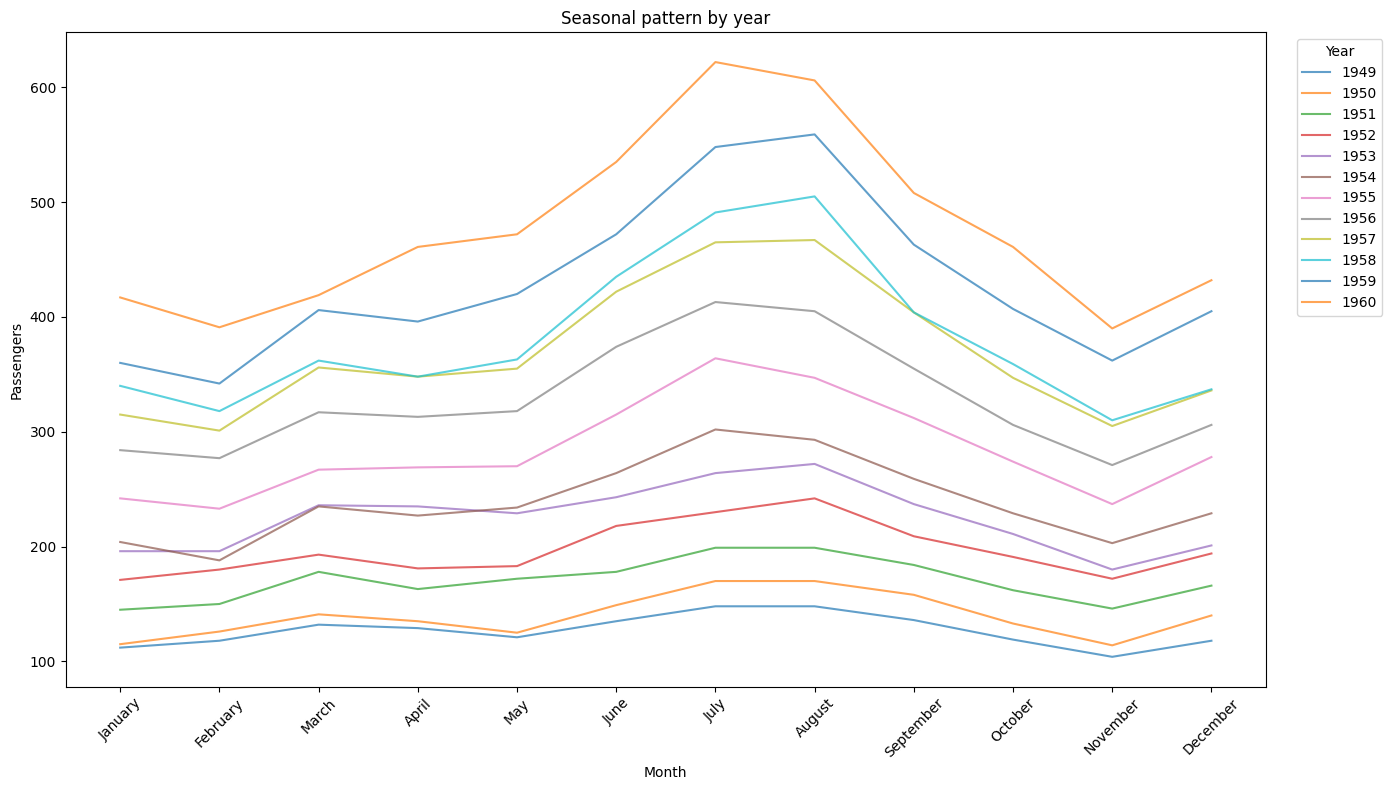

In [3]:
month_order = ['January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December']
month_map = {m: i for i, m in enumerate(month_order)}
df['month_order'] = df['month'].map(month_map)

plt.figure(figsize=(14, 8))
for year, group in df.groupby('year'):
    plt.plot(group['month'], group['passengers'], alpha=0.7, label=year)
plt.title('Seasonal pattern by year')
plt.xlabel('Month')
plt.ylabel('Passengers')
plt.xticks(rotation=45)
plt.legend(title='Year', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


## 3) Which month is consistently busiest?
A monthly average is the clearest way to show the typical seasonal peak.


/var/folders/b7/n66x67qj3_57sghtm4d552j00000gn/T/ipykernel_90588/1291343765.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=monthly_avg, x='month', y='passengers', palette='Blues')


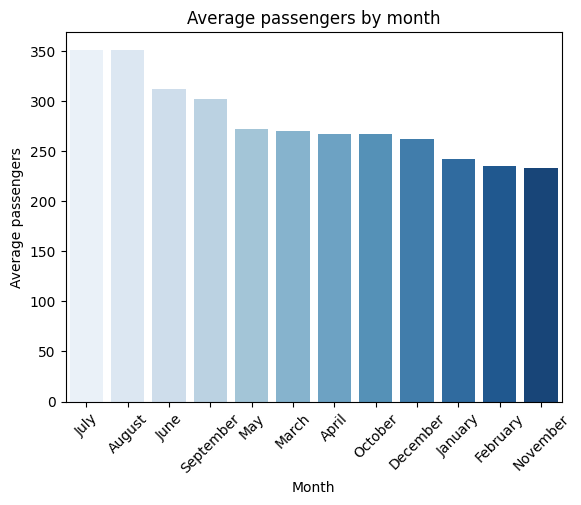

In [4]:
monthly_avg = df.groupby('month', as_index=False)['passengers'].mean()
monthly_avg = monthly_avg.sort_values('passengers', ascending=False).reset_index(drop=True)

sns.barplot(data=monthly_avg, x='month', y='passengers', palette='Blues')
plt.title('Average passengers by month')
plt.xlabel('Month')
plt.ylabel('Average passengers')
plt.xticks(rotation=45)
plt.show()


## 4) Which chart belongs in a report?
The first chart is the best report chart because it combines the long-term trend and the seasonal rhythm in one clear narrative. The seasonal-by-year chart is useful for analysis but too crowded for a report. The monthly average is good for highlighting the peak month, but it hides the changing level over time.

The larger seasonal swing every year is not necessarily evidence that the seasonal fluctuation is getting stronger. It is partly a consequence of the airline being larger overall. A good way to settle this is to plot the seasonal amplitude as a percentage of the annual level, or to show month-over-month seasonality normalized by the annual total.
